In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import json

## Reading the Excel File and Printing the Columns

In [2]:
df = pd.read_excel('Sample Data Purchases (First Purchase Only).xlsx')
df.columns

Index(['ID', 'Purchase Timestamp Time',
       'Purchase Order (Tells this is the nth purchase of user)', 'User ID',
       'Event Name', 'Product ID', 'LA Purchase Amount (USD)',
       'Event Parameters'],
      dtype='str')

## Aggregate Product-Level Insights

In [3]:
product_analysis = df.groupby('Product ID').agg(
    unique_users = ('User ID', 'nunique'),
    total_revenue = ('LA Purchase Amount (USD)', 'sum'),
    avg_price = ('LA Purchase Amount (USD)', 'mean')
).reset_index()

In [4]:
product_analysis['Product ID'] = product_analysis['Product ID'].str.replace(
    'com.gamebrain.hexasort.', '', regex = False
)
product_analysis['Product ID'] = product_analysis['Product ID'].str.replace(
    'blossomavenue.', '', regex = False
)
product_analysis['Product ID'] = product_analysis['Product ID'].str.replace(
    'default.', '', regex = False
)

In [5]:
product_analysis[['Product ID', 'unique_users']]

,Product ID,unique_users
0,goldpass,333
1,ultimategoldpass,684
2,coinpack1,7577
3,coinpack2,1180
4,coinpack3,367
5,coinpack4,93
6,coinpack5,43
7,coinpack6,25
8,oneononeoffer,247
9,freelivesrefillbundle,686


In [6]:
product_analysis[['Product ID', 'total_revenue']]

,Product ID,total_revenue
0,goldpass,2660.67
1,ultimategoldpass,6833.16
2,coinpack1,15078.23
3,coinpack2,9428.20
4,coinpack3,5501.33
5,coinpack4,2789.07
6,coinpack5,2149.57
7,coinpack6,2499.75
8,oneononeoffer,1726.53
9,freelivesrefillbundle,6853.14


## Plots (For Visualization)

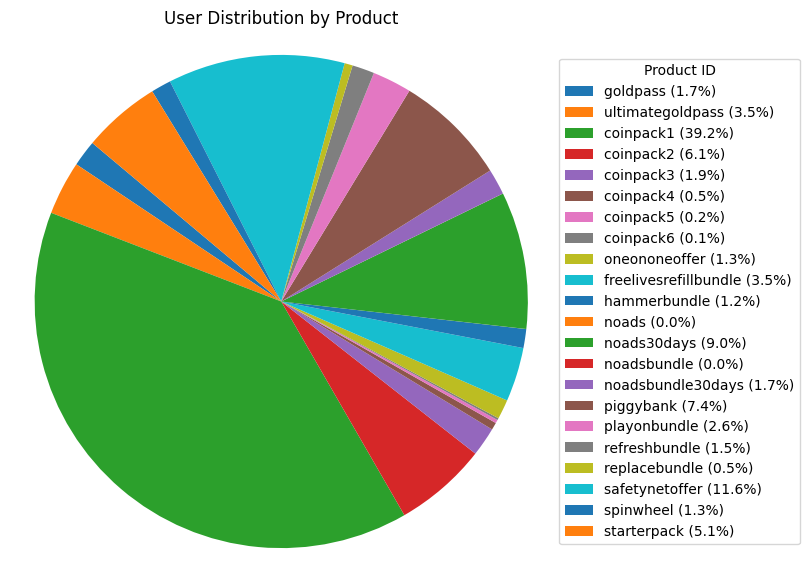

In [7]:
total_users = product_analysis['unique_users'].sum()
percentages = (product_analysis['unique_users'] / total_users) * 100

legend_labels = [
    f"{prod} ({pct:.1f}%)"
    for prod, pct in zip(product_analysis['Product ID'], percentages)
]

plt.figure(figsize = (7, 7))

wedges, texts = plt.pie(
    product_analysis['unique_users'],
    startangle = 140
)

plt.legend(
    wedges,
    legend_labels,
    title = 'Product ID',
    loc = 'center left',
    bbox_to_anchor = (1, 0.5)
)

plt.title('User Distribution by Product')
plt.axis('equal')

plt.show()

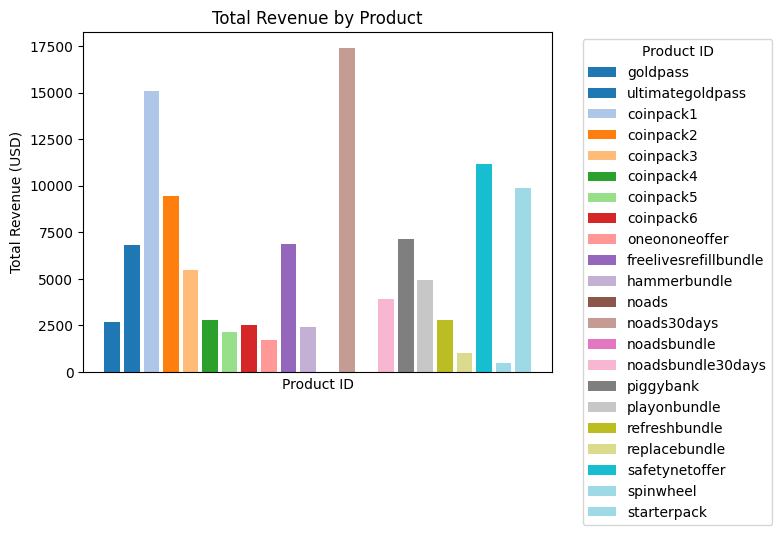

In [8]:
plt.figure(figsize = (8, 5))

colors = plt.cm.tab20(np.linspace(0, 1, len(product_analysis)))

bars = plt.bar(
    product_analysis['Product ID'],
    product_analysis['total_revenue'],
    color = colors
)

# Create legend labels
legend_labels = product_analysis['Product ID']

plt.legend(
    bars,
    legend_labels,
    title = 'Product ID',
    bbox_to_anchor = (1.05, 1),
    loc = 'upper left'
)

plt.xticks([])
plt.xlabel('Product ID')
plt.ylabel('Total Revenue (USD)')
plt.title('Total Revenue by Product')

plt.tight_layout()
plt.show()

## Parsing Event Parameters

In [46]:
def safe_json_load(x):
    try:
        return json.loads(x)
    except:
        return {}

def extract_features(row):
    data = row['event_params_parsed']
    
    additional_data = safe_json_load(data.get('additional_data'))
    level_info = safe_json_load(additional_data.get('level_info')) if additional_data else {}
    transaction = safe_json_load(data.get('transaction'))
    
    virtual_currency_amount = None
    vc_list = transaction.get('productReceived', {}).get('virtualCurrencies', [])

    if isinstance(vc_list, list) and len(vc_list) > 0:
        virtual_currency_amount = vc_list[0].get('virtualCurrencyAmount', None)
    
    return pd.Series({
        'device_os': data.get('os_name', None),
        'device_model': data.get('device_name', None),
        
        'engagement_time': data.get('time_in_app', None),
        
        'user_level': data.get('user_level', None),
        
        'total_blocked_cells': level_info.get('total_blocked_cells', None) if level_info else None,
        
        'virtual_currency_amount': virtual_currency_amount
    })

In [47]:
df['event_params_parsed'] = df['Event Parameters'].apply(safe_json_load)
features_df = df.apply(extract_features, axis = 1)

In [60]:
final_df = pd.concat([
    df[['User ID', 'Product ID', 'LA Purchase Amount (USD)']],
    features_df
], axis = 1)

In [61]:
final_df.head()

,User ID,Product ID,LA Purchase Amount (USD),device_os,device_model,engagement_time,user_level,total_blocked_cells,virtual_currency_amount
0,c9442a2f50e88e44f7344f7f8b7f192a,com.gamebrain.hexasort.coinpack3,14.99,ios,iPhone14Pro,3013,7,8.0,1800.0
1,abc2cc570ff2186db484eea46f81e6fa,com.gamebrain.hexasort.starterpack,9.99,ios,iPhone13,1729,5,2.0,1000.0
2,914b3d950a6d1c438b9503dfce8bea54,com.gamebrain.hexasort.starterpack,9.99,ios,iPadAir4,132,1,NaN,1000.0
3,faaf24a1647bc9f021c29f0506f7c238,com.gamebrain.hexasort.starterpack,9.99,ios,iPhone15Pro,2189,7,8.0,1000.0
4,4443daa77b473620903c5a5f216cf9bc,com.gamebrain.hexasort.safetynetoffer,4.98,ios,iPhone13ProMax,2874,8,5.0,500.0


In [62]:
print(final_df.shape)
final_df.dropna().shape

(19342, 9)


(12194, 9)

In [63]:
final_df = final_df.dropna()

In [64]:
final_df.head()

,User ID,Product ID,LA Purchase Amount (USD),device_os,device_model,engagement_time,user_level,total_blocked_cells,virtual_currency_amount
0,c9442a2f50e88e44f7344f7f8b7f192a,com.gamebrain.hexasort.coinpack3,14.99,ios,iPhone14Pro,3013,7,8.0,1800.0
1,abc2cc570ff2186db484eea46f81e6fa,com.gamebrain.hexasort.starterpack,9.99,ios,iPhone13,1729,5,2.0,1000.0
3,faaf24a1647bc9f021c29f0506f7c238,com.gamebrain.hexasort.starterpack,9.99,ios,iPhone15Pro,2189,7,8.0,1000.0
4,4443daa77b473620903c5a5f216cf9bc,com.gamebrain.hexasort.safetynetoffer,4.98,ios,iPhone13ProMax,2874,8,5.0,500.0
6,960e91472b01c08c693c66659ee6844a,com.gamebrain.hexasort.coinpack2,7.99,ios,iPhone14ProMax,747,3,0.0,700.0


## Plots

In [65]:
final_df['engagement_time'] = pd.to_numeric(final_df['engagement_time'], errors = 'coerce')
bins = np.logspace(
    np.log10(final_df['engagement_time'].min() + 1),
    np.log10(final_df['engagement_time'].max()),
    12
)
final_df['engagement_bin'] = pd.cut(final_df['engagement_time'], bins = bins)

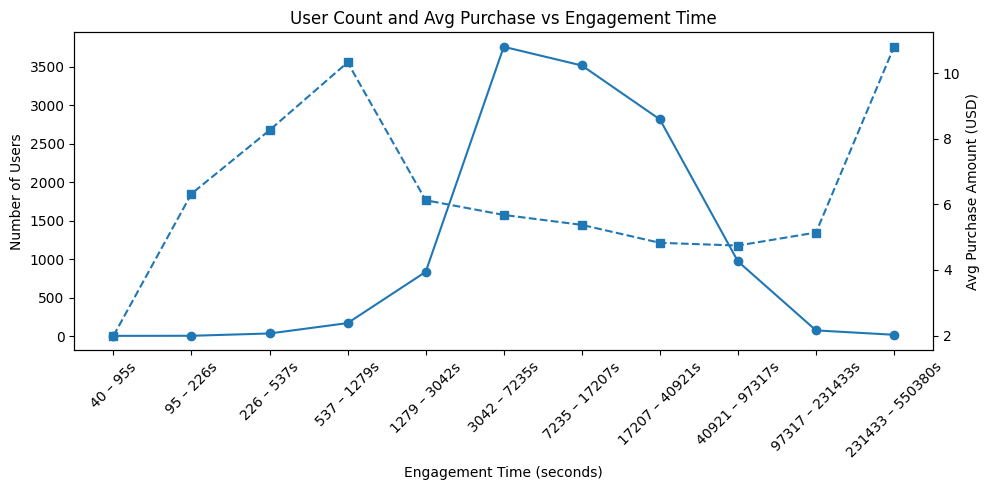

In [66]:
grouped = final_df.groupby('engagement_bin')

engagement_counts = grouped['User ID'].count()
avg_purchase = grouped['LA Purchase Amount (USD)'].mean()

labels = [
    f'{int(interval.left)} – {int(interval.right)}s'
    for interval in engagement_counts.index
]

fig, ax1 = plt.subplots(figsize = (10, 5))

ax1.plot(labels, engagement_counts.values, marker = 'o')
ax1.set_xlabel('Engagement Time (seconds)')
ax1.set_ylabel('Number of Users')
ax1.tick_params(axis = 'x', rotation = 45)

ax2 = ax1.twinx()
ax2.plot(labels, avg_purchase.values, marker = 's', linestyle = '--')
ax2.set_ylabel('Avg Purchase Amount (USD)')

plt.title('User Count and Avg Purchase vs Engagement Time')

plt.tight_layout()
plt.show()

In [72]:
final_df['user_level'] = pd.to_numeric(final_df['user_level'], errors = 'coerce')
bins = np.logspace(
    np.log10(final_df['user_level'].min() + 1),
    np.log10(final_df['user_level'].max()),
    10
)
final_df['user_bin'] = pd.cut(final_df['user_level'], bins = bins)

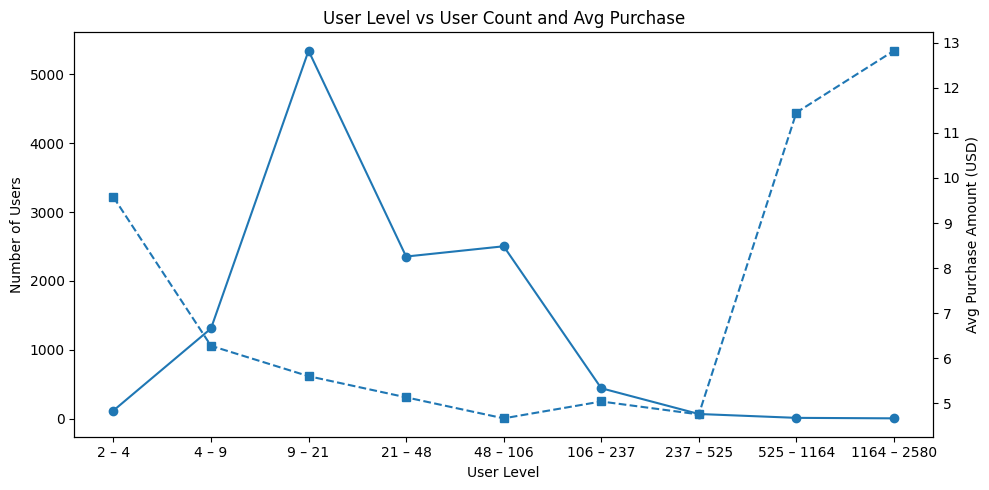

In [73]:
grouped = final_df.groupby('user_bin')

user_counts = grouped['User ID'].count()
avg_purchase = grouped['LA Purchase Amount (USD)'].mean()

labels = [
    f'{int(interval.left)} – {int(interval.right)}'
    for interval in user_counts.index
]

fig, ax1 = plt.subplots(figsize = (10, 5))

# User count
ax1.plot(labels, user_counts.values, marker = 'o')
ax1.set_xlabel('User Level')
ax1.set_ylabel('Number of Users')

# Avg purchase
ax2 = ax1.twinx()
ax2.plot(labels, avg_purchase.values, marker = 's', linestyle = '--')
ax2.set_ylabel('Avg Purchase Amount (USD)')

plt.title('User Level vs User Count and Avg Purchase')

plt.tight_layout()
plt.show()